# 2. Clustering Anjing (K-Means)

Tujuan: mengelompokkan anjing berdasarkan **umur**, **ukuran**, dan **panjang bulu**, lalu memberi nama tiap kelompok. Label ini dipakai di katalog aplikasi.

Langkah:
1. Ambil 3 fitur dari `data/dogs_clean.csv`.
2. Umur diubah dengan `log1p` karena sebarannya sangat miring (kebanyakan anak anjing, tapi ada yang sampai 255 bulan).
3. Semua fitur disamakan skalanya dengan `StandardScaler`.
4. Pilih jumlah cluster dengan melihat elbow dan silhouette score.
5. Latih K-Means, beri nama cluster, visualisasi dengan PCA.
6. Simpan model ke `models/kmeans.joblib` dan data ke `data/dogs_clustered.csv`.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

## Membaca data bersih

In [2]:
dogs = pd.read_csv("../data/dogs_clean.csv")
fitur = ["Age", "ukuran_angka", "bulu_angka"]
X = dogs[fitur]
print("Jumlah anjing:", len(dogs))
X.describe()

Jumlah anjing: 6528


,Age,ukuran_angka,bulu_angka
count,6528.000000,6528.000000,6528.000000
mean,14.366575,1.942708,1.488511
std,22.520371,0.496128,0.597110
min,0.000000,1.000000,1.000000
25%,2.000000,2.000000,1.000000
50%,4.000000,2.000000,1.000000
75%,16.000000,2.000000,2.000000
max,255.000000,3.000000,3.000000


## Memilih jumlah cluster

Model dibuat sebagai **pipeline**: `log1p` → `StandardScaler` → `KMeans`. Dengan pipeline, anjing baru di aplikasi Flask cukup dimasukkan ke model yang sama tanpa perlu menulis ulang langkah-langkahnya.

Dicoba k = 2 sampai 6. Silhouette score mendekati 1 berarti cluster terpisah dengan baik.

In [3]:
def buat_model(k):
    return make_pipeline(
        FunctionTransformer(np.log1p),
        StandardScaler(),
        KMeans(n_clusters=k, random_state=42, n_init=10),
    )

hasil = []
for k in range(2, 7):
    model = buat_model(k)
    label = model.fit_predict(X)
    X_skala = model[:-1].transform(X)
    skor = silhouette_score(X_skala, label, sample_size=3000, random_state=42)
    hasil.append({"k": k, "inertia": model[-1].inertia_, "silhouette": round(skor, 3)})

hasil = pd.DataFrame(hasil)
hasil

,k,inertia,silhouette
0,2,13423.410207,0.390
1,3,9240.821687,0.459
2,4,6777.619618,0.494
3,5,5287.890658,0.527
4,6,4002.485399,0.556


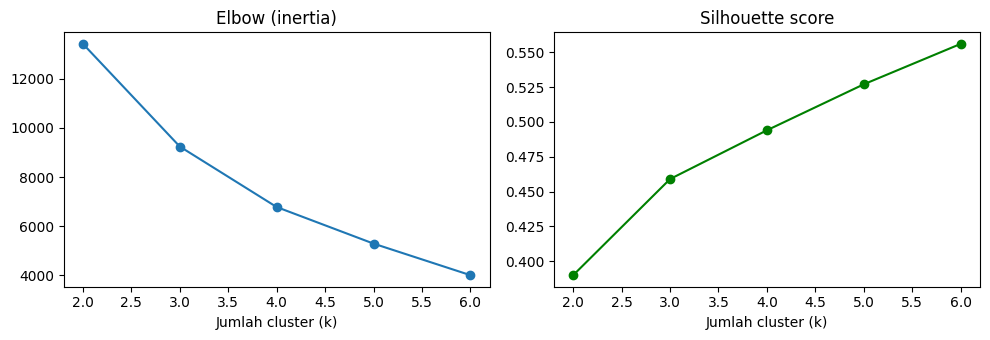

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hasil["k"], hasil["inertia"], marker="o")
ax[0].set_title("Elbow (inertia)")
ax[0].set_xlabel("Jumlah cluster (k)")
ax[1].plot(hasil["k"], hasil["silhouette"], marker="o", color="green")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("Jumlah cluster (k)")
plt.tight_layout()
plt.show()

**Pilihan: k = 4.** Silhouette score memang terus naik kalau k ditambah, karena ukuran dan bulu hanya punya 3 nilai sehingga data mudah dipecah. Tapi makin banyak cluster, makin sulit diberi nama yang bermakna untuk calon adopter. Dengan k = 4, silhouette sudah cukup baik (sekitar 0,49) dan tiap cluster masih mudah dijelaskan.

## Melatih K-Means dengan k = 4

In [5]:
K = 4
model = buat_model(K)
dogs["cluster"] = model.fit_predict(X)
print(dogs["cluster"].value_counts().sort_index())

cluster
0    1180
1    1745
2    1001
3    2602
Name: count, dtype: int64


## Profil tiap cluster

Nama cluster ditentukan dari profil ini: umur median, ukuran terbanyak, dan bulu terbanyak.

In [6]:
profil = dogs.groupby("cluster").agg(
    jumlah=("Age", "size"),
    umur_median=("Age", "median"),
    ukuran_terbanyak=("MaturitySize", lambda s: s.mode()[0]),
    persen_kecil=("MaturitySize", lambda s: round((s == "Small").mean() * 100)),
    bulu_terbanyak=("FurLength", lambda s: s.mode()[0]),
    rata_kecepatan_adopsi=("AdoptionSpeed", "mean"),
).round(2)
profil

,jumlah,umur_median,ukuran_terbanyak,persen_kecil,bulu_terbanyak,rata_kecepatan_adopsi
cluster,,,,,,
0,1180,36.0,Medium,0,Short,2.91
1,1745,2.0,Medium,0,Medium,2.43
2,1001,12.0,Small,100,Short,2.39
3,2602,3.0,Medium,0,Short,2.60


Aturan pemberian nama (dibuat dari tabel profil di atas, supaya nama tetap benar walaupun nomor cluster berubah):
- Hampir semua berukuran kecil → **Anjing kecil**
- Umur median 12 bulan atau lebih → **Dewasa sedang–besar**
- Anak anjing dengan bulu pendek → **Anak anjing bulu pendek**
- Anak anjing dengan bulu sedang atau panjang → **Anak anjing bulu lebat**

In [7]:
def beri_nama(baris):
    if baris["persen_kecil"] >= 90:
        return "Anjing kecil"
    if baris["umur_median"] >= 12:
        return "Dewasa sedang–besar"
    if baris["bulu_terbanyak"] == "Short":
        return "Anak anjing bulu pendek"
    return "Anak anjing bulu lebat"

nama_cluster = profil.apply(beri_nama, axis=1).to_dict()
dogs["cluster_label"] = dogs["cluster"].map(nama_cluster)
nama_cluster

{0: 'Dewasa sedang–besar',
 1: 'Anak anjing bulu lebat',
 2: 'Anjing kecil',
 3: 'Anak anjing bulu pendek'}

## Visualisasi dengan PCA

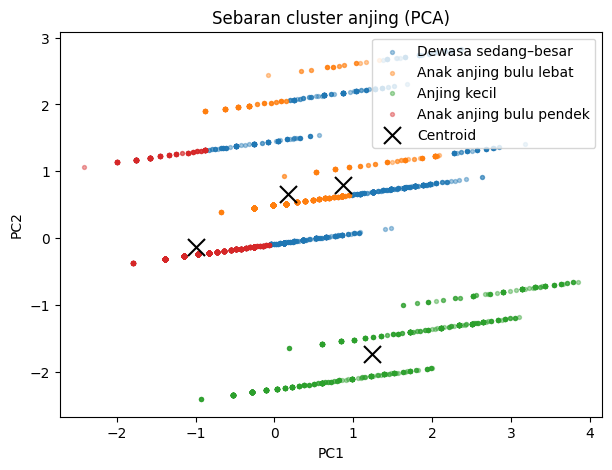

In [8]:
X_skala = model[:-1].transform(X)
pca = PCA(n_components=2, random_state=42)
titik = pca.fit_transform(X_skala)
pusat = pca.transform(model[-1].cluster_centers_)

plt.figure(figsize=(7, 5))
for c in sorted(dogs["cluster"].unique()):
    bagian = dogs["cluster"] == c
    plt.scatter(titik[bagian, 0], titik[bagian, 1], s=8, alpha=0.4, label=nama_cluster[c])
plt.scatter(pusat[:, 0], pusat[:, 1], marker="x", s=150, c="black", label="Centroid")
plt.title("Sebaran cluster anjing (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

## Simpan model dan hasil

In [9]:
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": model, "fitur": fitur, "nama_cluster": nama_cluster}, "../models/kmeans.joblib")
dogs.to_csv("../data/dogs_clustered.csv", index=False)
print("Model tersimpan di models/kmeans.joblib")
print("Data tersimpan di data/dogs_clustered.csv:", dogs.shape)

Model tersimpan di models/kmeans.joblib
Data tersimpan di data/dogs_clustered.csv: (6528, 24)


## Contoh: memberi label untuk anjing baru

In [10]:
baru = pd.DataFrame([{"Age": 30, "ukuran_angka": 3, "bulu_angka": 1}])
c = model.predict(baru[fitur])[0]
print("Anjing baru masuk cluster", c, "→", nama_cluster[c])

Anjing baru masuk cluster 0 → Dewasa sedang–besar
